# Pretraining on OSSL

> Train one CNN for each of clay, pH and K on OSSL, without the ring-trial soils

In [ ]:
#| default_exp pretrain

In [ ]:
#| export
from pathlib import Path
import numpy as np, pandas as pd
from soilspectfm.preprocessing import SNV
from soilspecdl.all import SpectralCNN, train_or_load, load_weights
from ossl_rt_transfer.data import data_path, ossl_props, ossl_overlap

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
from fastcore.test import *
from soilspecdata.datasets.ossl import load_ossl

The cells that read OSSL are marked `#| rtdata`, like the ring-trial cells of `00_data`, and `nbdev-test` skips them unless you run `nbdev-test --flags rtdata`. The outputs on this page come from a local run on an Apple silicon GPU (MPS).

## Training data

In [ ]:
#| export
rt_wns = np.arange(650, 4001, 2) # Wavenumbers of the ring-trial spectra, in cm⁻¹
log_props = ['potassium_cmolkg'] # Ring-trial properties that the models predict as `log1p`

def ossl_xy(
    ossl_mir, # OSSL MIR `Spectra` on `rt_wns`, such as `load_ossl().mir(650, 4000)`
    prop, # Ring-trial property, a key of `ossl_props`
)->tuple: # Spectra, targets and OSSL IDs
    "The OSSL samples that have a value of `prop`, without the ring-trial soils in `ossl_overlap`"
    assert np.array_equal(ossl_mir.wavenumbers, rt_wns), "The OSSL spectra need the wavenumbers `rt_wns`"
    X, y, ids = ossl_mir.xy(ossl_props[prop])
    keep, y = ~np.isin(ids, ossl_overlap), y.ravel()
    return X[keep], np.log1p(y[keep]) if prop in log_props else y[keep], ids[keep]

The OSSL spectra on the ring-trial grid. Each property has its own set of samples, because some samples lack some properties:

In [ ]:
#| rtdata
om = load_ossl().mir(650, 4000)
data = {p: ossl_xy(om, p) for p in ossl_props}
for X, y, ids in data.values(): test_eq(np.isin(ids, ossl_overlap).sum(), 0)
pd.DataFrame({p: {'samples': len(y), 'min': y.min(), 'median': np.median(y), 'max': y.max()} for p, (X, y, ids) in data.items()}).T.round(2)

,samples,min,median,max
clay_perc,56391.0,0.00,21.85,100.00
pH_H20,59370.0,1.97,6.23,10.70
potassium_cmolkg,57636.0,0.00,0.30,3.65


K is skewed: in OSSL, 99% of the values are below 4.8 cmolc/kg, and the largest is 37.6. As in `ossl-fuku-transfer`, the K model predicts `log1p(K)`, and the table above gives `log1p` values for it. The clay and pH models predict the values as they are.

## Preprocessing

In [ ]:
#| export
def preprocess()->SNV: # Unfitted transform
    "SNV of each spectrum, the only preprocessing"
    return SNV()


SNV works on each spectrum separately, so fitting it on OSSL learns nothing that would differ for a ring-trial instrument. There is no derivative filter: the first convolutions of the CNN can learn derivative-like filters if they help.


## Pretraining

In [ ]:
#| export
def model_dir()->Path: # Folder of pretrained weights and training histories
    "`models/ossl-rt-transfer` in `data_path()`"
    p = data_path()/'models'/'ossl-rt-transfer'
    p.mkdir(parents=True, exist_ok=True)
    return p

def pretrain(
    X, # Preprocessed OSSL spectra, on `rt_wns`
    y, # Targets, from `ossl_xy`
    fname, # File name for the weights, without extension
    seed=42, # Seed for the validation split and the training
    epochs=80, # Number of one-cycle epochs
    lr=1e-3, # Maximum learning rate
)->SpectralCNN: # The trained model, on the CPU
    "Train a `SpectralCNN` on OSSL, or load the weights that an earlier run saved under `fname`"
    return train_or_load(model_dir()/f'{fname}.pth', X, y, rt_wns, epochs=epochs, lr=lr, seed=seed)

def load_pretrained(fname)->SpectralCNN: # The model, on the CPU
    "Load the weights that `pretrain` saved under `fname`"
    return load_weights(model_dir()/f'{fname}.pth')

def pretrain_history(fname)->pd.DataFrame: # One row per epoch: losses and validation R²
    "The training history that `pretrain` saved under `fname`"
    return pd.read_csv(model_dir()/f'{fname}.csv', index_col='epoch')

The training settings are those of `ossl-fuku-transfer`, a maximum learning rate of 10⁻³ with 10% of the samples for validation, except the number of epochs. Training runs for 80 one-cycle epochs, the number chosen in the section below. One model per property, saved as `ossl_<property>_snv_ep80`. The table gives the last epoch, with the R² of the OSSL validation set:

In [ ]:
#| rtdata
fnames = {p: f'ossl_{p}_snv_ep80' for p in ossl_props}
for p, (X, y, ids) in data.items(): pretrain(preprocess().fit_transform(X), y, fnames[p])
pd.DataFrame({p: pretrain_history(f).iloc[-1] for p, f in fnames.items()}).T.round(3)

,train_loss,valid_loss,r2_score
clay_perc,14.716,22.462,0.924
pH_H20,0.116,0.120,0.931
potassium_cmolkg,0.021,0.026,0.822


The validation R² of the K model is on `log1p(K)`.

The learning curves of the three models, with validation loss as solid lines and training loss as dashed lines. Each property has its own loss scale, so each has its own panel:

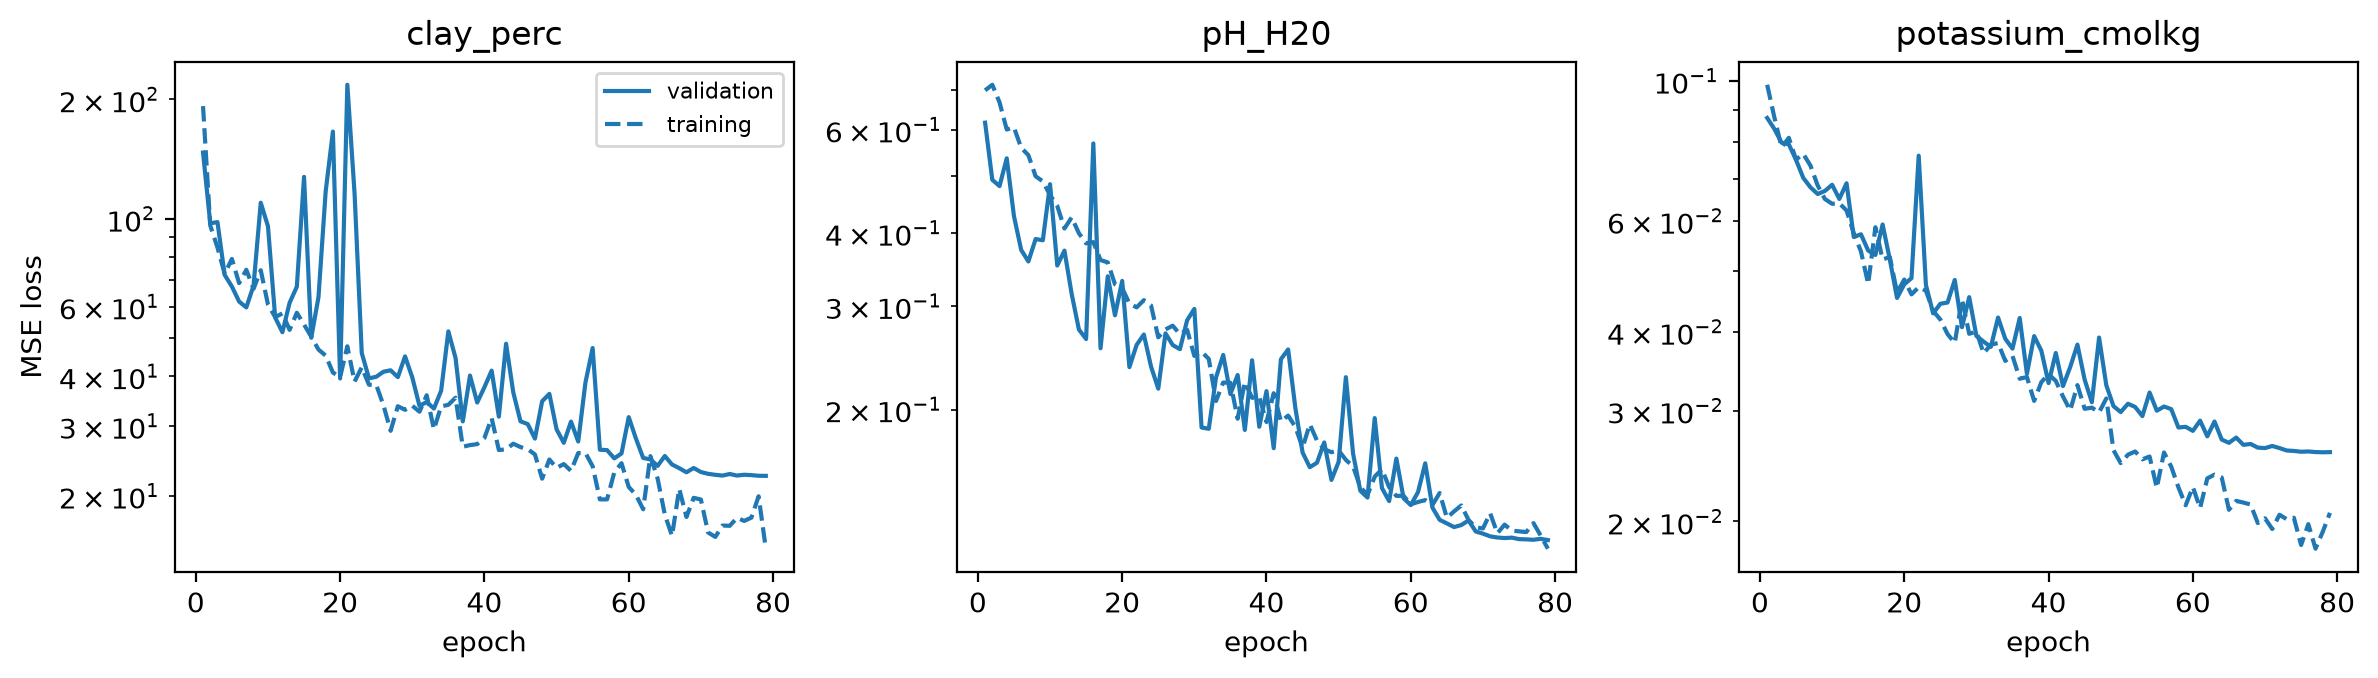

In [ ]:
#| rtdata
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (p, f) in zip(axs, fnames.items()):
    h = pretrain_history(f).iloc[1:]
    ax.plot(h.index, h.valid_loss, 'C0', label='validation')
    ax.plot(h.index, h.train_loss, 'C0', ls='--', label='training')
    ax.set(title=p, xlabel='epoch', yscale='log')
axs[0].set_ylabel('MSE loss'); axs[0].legend(fontsize=8)
plt.tight_layout();

In [ ]:
#| rtdata
test_eq(load_pretrained(fnames['pH_H20']).state_dict().keys(), SpectralCNN().state_dict().keys())

## Number of epochs

Without a derivative, the CNN may need more epochs to reach the same validation R². The clay model trains again with 40 and 80 epochs, with the other settings unchanged. The table gives the last epoch of each run:

In [ ]:
#| rtdata
X, y, _ = data['clay_perc']
Xp, eps = preprocess().fit_transform(X), [20, 40, 80]
ep_fnames = {e: f'ossl_clay_perc_snv_ep{e}' for e in eps}
for e in eps: pretrain(Xp, y, ep_fnames[e], epochs=e)
pd.DataFrame({e: pretrain_history(f).iloc[-1] for e, f in ep_fnames.items()}).T.rename_axis('epochs').round(3)

,train_loss,valid_loss,r2_score
epochs,,,
20,28.588,34.807,0.883
40,21.178,28.613,0.904
80,14.716,22.462,0.924


The learning curves show whether the validation loss is still falling at the end of each run. Each run has its own one-cycle schedule, so the 20- and 40-epoch curves are not the start of the 80-epoch curve.

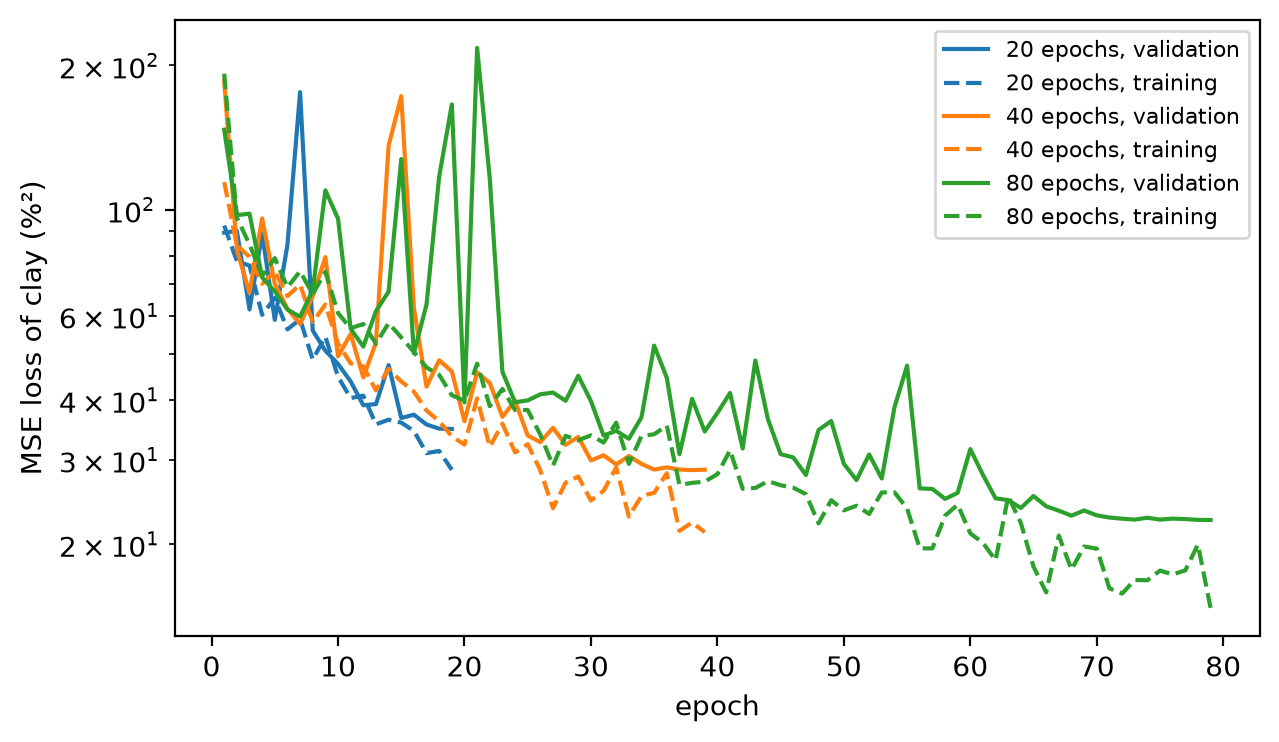

In [ ]:
#| rtdata
fig, ax = plt.subplots(figsize=(7, 4))
for (e, f), col in zip(ep_fnames.items(), ['C0', 'C1', 'C2']):
    h = pretrain_history(f).iloc[1:]
    ax.plot(h.index, h.valid_loss, col, label=f'{e} epochs, validation')
    ax.plot(h.index, h.train_loss, col, ls='--', label=f'{e} epochs, training')
ax.set(xlabel='epoch', ylabel='MSE loss of clay (%²)', yscale='log')
ax.legend(fontsize=8);

The 80-epoch run gives the lowest validation loss. Its validation loss is flat over the last 10 epochs and does not rise, so the model does not overfit yet. Training uses 80 epochs for every property.